# Option 1 site intake

Enter any Massachusetts latitude/longitude pair. Collect existing property, electrical, electricity/rate, equipment and historical-document evidence with provenance and missing-data flags. No designs, code/submission checks, compliance lifecycle fields, environmental screening or municipality-only PTS records are included. Supplied example files are not inputs.

The API uses schema 2.1 and six intake groups. The table includes explicit measurement units and the requested column order. Non-measurements are `not_applicable`; unresolved units are `unknown`.

In [1]:
import json
from pathlib import Path

import polars as pl
from IPython.display import FileLink, Image, display
from API import lookup_site, checklist_table

LATITUDE, LONGITUDE = 42.2626, -71.8023

site = lookup_site(LATITUDE, LONGITUDE)
table = checklist_table(site)
with pl.Config(tbl_rows=60, tbl_cols=-1, fmt_str_lengths=80):
    display(table.head(60))
print("Sources:", {name: result["status"] for name, result in site["sources"].items()})
print("Site evidence folder:", site["evidence"]["site_directory"])
print("This run:", site["evidence"]["directory"])

display(pl.from_dicts(site["public_coverage"]).select("source", "status", "records", "truncated", "detail"))

checklist item,subcategory_name,subcategory_value,value_unit_of_measurement,source_title,fetched_at_utc,checked_at_utc,source_date,source_date_basis,searched_latitude,searched_longitude,source_latitude,source_longitude,source_distance_m,source_location_basis,data_source,local_file,file_url
str,str,str,str,str,str,str,str,str,f64,f64,f64,f64,f64,str,str,str,str
"""Site and property""","""address""","""455 MAIN ST""","""not_applicable""","""MassGIS — Massachusetts assessor parcels""","""2026-11-07T23:07:24.438343+00:00""","""2026-11-07T23:07:24.438343+00:00""","""2026""","""Assessor fiscal year FY; not an ownership verification date""",42.2626,-71.8023,42.262513,-71.801582,59.88,"""Provider polygon centroid in WGS84; not a meter or neighboring-site match""","""https://services1.arcgis.com/hGdibHYSPO59RG1h/arcgis/rest/services/Massachusetts…","""/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAnd…","""/evidence/42.262600_-71.802300/runs/20261107T230726592334Z/parcels.json"""
"""Site and property""","""municipality""","""WORCESTER""","""not_applicable""","""MassGIS — electricity providers by municipality""","""2026-11-07T23:07:24.143228+00:00""","""2026-11-07T23:07:24.143228+00:00""",null,"""Source does not supply a record date""",42.2626,-71.8023,null,null,null,"""Municipality-wide record; no site coordinate supplied""","""https://arcgisserver.digital.mass.gov/arcgisserver/rest/services/AGOL/Electricit…","""/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAnd…","""/evidence/42.262600_-71.802300/runs/20261107T230726592334Z/utilities.json"""
"""Site and property""","""state""","""MA""","""not_applicable""","""MassGIS — electricity providers by municipality""","""2026-11-07T23:07:24.143228+00:00""","""2026-11-07T23:07:24.143228+00:00""",null,"""Source does not supply a record date""",42.2626,-71.8023,null,null,null,"""Municipality-wide record; no site coordinate supplied""","""https://arcgisserver.digital.mass.gov/arcgisserver/rest/services/AGOL/Electricit…","""/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAnd…","""/evidence/42.262600_-71.802300/runs/20261107T230726592334Z/utilities.json"""
"""Site and property""","""latitude""","""42.2626""","""degrees (WGS84)""","""Coordinates supplied by the caller""","""2026-11-07T23:07:26.592163+00:00""",null,null,"""Caller supplied location; observation date unknown""",42.2626,-71.8023,42.2626,-71.8023,0.0,"""Caller-provided coordinate""","""User-provided coordinates""",null,null
"""Site and property""","""longitude""","""-71.8023""","""degrees (WGS84)""","""Coordinates supplied by the caller""","""2026-11-07T23:07:26.592163+00:00""",null,null,"""Caller supplied location; observation date unknown""",42.2626,-71.8023,42.2626,-71.8023,0.0,"""Caller-provided coordinate""","""User-provided coordinates""",null,null
"""Site and property""","""parcel_id""","""F_574532_2920828""","""not_applicable""","""MassGIS — Massachusetts assessor parcels""","""2026-11-07T23:07:24.438343+00:00""","""2026-11-07T23:07:24.438343+00:00""","""2006-09-06""","""Parcel geometry LAST_EDIT; not a title verification date""",42.2626,-71.8023,42.262513,-71.801582,59.88,"""Provider polygon centroid in WGS84; not a meter or neighboring-site match""","""https://services1.arcgis.com/hGdibHYSPO59RG1h/arcgis/rest/services/Massachusetts…","""/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAnd…","""/evidence/42.262600_-71.802300/runs/20261107T230726592334Z/parcels.json"""
"""Site and property""","""municipal_parcel_id""","""02-024-00001""","""not_applicable""","""MassGIS — Massachusetts assessor parcels""","""2026-11-07T23:07:24.438343+00:00""","""2026-11-07T23:07:24.438343+00:00""","""2026""","""Assessor fiscal year FY; not an ownership verification date""",42.2626,-71.8023,42.262513,-71.801582,59.88,"""Provider polygon centroid in WGS84; not a meter or neighboring-site match""","""https://services1.arcgis.com/hGdibHY

Sources: {'utilities': 'ok', 'parcels': 'ok', 'buildings': 'no_data', 'lber': 'ok', 'permits': 'unsupported', 'electrical_permits': 'unsupported', 'solar_permits': 'unsupported', 'assessor_records': 'unsupported', 'municipal_archives': 'unsupported', 'land_records': 'partial', 'tariffs': 'partial'}
Site evidence folder: /Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/evidence/42.262600_-71.802300
This run: /Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/evidence/42.262600_-71.802300/runs/20261107T230726592334Z


source,status,records,truncated,detail
str,str,i64,bool,str
"""utilities""","""ok""",1,false,null
"""parcels""","""ok""",1,false,null
"""buildings""","""no_data""",0,false,null
"""lber""","""ok""",45,false,null
"""permits""","""unsupported""",0,false,"""This permit adapter covers Cam…"
…,…,…,…,…
"""solar_permits""","""unsupported""",0,false,"""This permit adapter covers Cam…"
"""assessor_records""","""unsupported""",0,false,"""No public assessor adapter con…"
"""municipal_archives""","""unsupported""",0,false,"""Municipal archive adapter curr…"


In [2]:
assert site["scope"] == "option_1_site_intake"
assert len(site["checklist"]) == 6
assert set(site["sources"]) == {"utilities", "parcels", "buildings", "lber", "permits", "electrical_permits", "solar_permits", "assessor_records", "municipal_archives", "land_records", "tariffs"}
assert table.to_dicts() == checklist_table(site, include_all=True).to_dicts()
print("Option 1 scope verified; compatibility view cannot restore removed fields.")

Option 1 scope verified; compatibility view cannot restore removed fields.


## Audit the measurement units

Areas retain their source unit (`acre` versus `ft²`), annual electricity is energy (`kWh`, with native `kBtu` retained), and solar power distinguishes system `kW DC` from panel `W/panel`. The permit storage checkbox is not an energy measurement. Nested quantities have their own rows. Date/location metadata units are fixed; `match_method` remains in full JSON.

In [3]:
from API.checklist_table import TABLE_COLUMNS

assert table.columns == TABLE_COLUMNS
assert table["value_unit_of_measurement"].is_not_null().all()
measurements = table.filter(pl.col("value_unit_of_measurement") != "not_applicable")
with pl.Config(tbl_cols=-1, fmt_str_lengths=80):
    display(measurements.select("subcategory_name", "subcategory_value", "value_unit_of_measurement", "source_title").head(30))
unknown_units = table.filter(pl.col("value_unit_of_measurement") == "unknown")
print("Rows with a measurement whose unit is not established:", unknown_units.height)
if unknown_units.height:
    display(unknown_units.select("subcategory_name", "subcategory_value", "source_title"))

subcategory_name,subcategory_value,value_unit_of_measurement,source_title
str,str,str,str
"""latitude""","""42.2626""","""degrees (WGS84)""","""Coordinates supplied by the caller"""
"""longitude""","""-71.8023""","""degrees (WGS84)""","""Coordinates supplied by the caller"""
"""assessor_building_area_sqft""","""97950""","""ft²""","""MassGIS — Massachusetts assessor parcels"""
"""parcel_land_area""","""3.66""","""acre""","""MassGIS — Massachusetts assessor parcels"""
"""year_built""","""1890""","""year""","""MassGIS — Massachusetts assessor parcels"""
…,…,…,…
"""annual_energy_candidates[3].Total_Electricity_Use_Purchased_From_Grid__kBtu_""","""0""","""kBtu""","""Massachusetts DOER — multi-year building energy disclosures"""
"""annual_energy_candidates[3].Total_Electricity_Generated_from_Onsite_Renewables__…","""0""","""kBtu""","""Massachusetts DOER — multi-year building energy disclosures"""
"""annual_energy_candidates[3].floor_area_sqft""","""27215""","""ft²""","""Massachusetts DOER — multi-year building energy disclosures"""


Rows with a measurement whose unit is not established: 0


## Confirm live retrieval

The file cache is revalidated on every request. `checked_at_utc` records the provider check, while `fetched_at_utc` records byte retrieval. HTTP 304 means the provider confirmed unchanged bytes. A changed file at the same URL is downloaded and preserved as a new version. Discovery failures are explicit; there is no fixed-year or fixed-file fallback. Publisher reports can legitimately remain old until the publisher releases an update.

In [4]:
freshness = [{
    "title": a["source_title"], "source_url": a["source_url"],
    "checked_at_utc": a.get("checked_at_utc"), "fetched_at_utc": a.get("fetched_at_utc"),
    "cache_status": a.get("cache_status"), "sha256": a.get("sha256"),
} for a in site["evidence"]["files"] if a.get("cache_status")]
display(pl.from_dicts(freshness, infer_schema_length=None))
print("LBER datasets:", site["sources"]["lber"].get("datasets"))
print("Selected imagery:", site["evidence"]["imagery_coverage"].get("dataset"))

title,source_url,checked_at_utc,fetched_at_utc,cache_status,sha256
str,str,str,str,str,str
"""MassGIS registries of deeds di…","""https://s3.us-east-1.amazonaws…","""2026-11-07T23:07:26.059936+00:…","""2026-11-07T22:42:53.271861+00:…","""revalidated_not_modified""","""f0b89f42bb879e24e0443e64d366e5…"
"""Massachusetts official electri…","""https://www.mass.gov/info-deta…","""2026-11-07T23:07:26.169785+00:…","""2026-11-07T23:07:26.169785+00:…","""downloaded""","""8d474471f3466a9fd1a14506e0609e…"
"""MassGIS 2025 parcel-envelope i…","""https://tiles.arcgis.com/tiles…","""2026-11-07T23:07:27.089841+00:…","""2026-11-07T22:42:53.815287+00:…","""revalidated_not_modified""","""817471de5443f9ab04e0a3f4b4ba70…"
"""MassGIS 2025 parcel-envelope i…","""https://tiles.arcgis.com/tiles…","""2026-11-07T23:07:27.151089+00:…","""2026-11-07T22:42:53.826822+00:…","""revalidated_not_modified""","""3120c062826fd00b685b8610855701…"
"""MassGIS 2025 parcel-envelope i…","""https://tiles.arcgis.com/tiles…","""2026-11-07T23:07:27.216297+00:…","""2026-11-07T22:42:53.838709+00:…","""revalidated_not_modified""","""7dcc4d94004d8098fda4ad1e1e22d7…"
"""MassGIS 2025 parcel-envelope i…","""https://tiles.arcgis.com/tiles…","""2026-11-07T23:07:27.280603+00:…","""2026-11-07T22:42:53.850045+00:…","""revalidated_not_modified""","""6f5665b092d22fe50f9255b8400790…"
"""MassGIS 2025 parcel-envelope i…","""https://tiles.arcgis.com/tiles…","""2026-11-07T23:07:27.336582+00:…","""2026-11-07T22:42:53.861523+00:…","""revalidated_not_modified""","""d7f3f9275c29f10a705b03f68f9b60…"
"""MassGIS 2025 parcel-envelope i…","""https://tiles.arcgis.com/tiles…","""2026-11-07T23:07:27.392791+00:…","""2026-11-07T22:42:53.872646+00:…","""revalidated_not_modified""","""d64a6a934c2378941fb883542d98b8…"


LBER datasets: [{'name': '2025_Annual_Report_Data', 'url': 'https://services1.arcgis.com/7iJyYTjCtKsZS1LR/arcgis/rest/services/2025_Annual_Report_Data/FeatureServer/0', 'item_id': '8c7ccf64faec400e84a739bbc4a4fbd9'}, {'name': '2026_10_28_LBER_Annual_Report_Data', 'url': 'https://services1.arcgis.com/7iJyYTjCtKsZS1LR/arcgis/rest/services/2026_10_28_LBER_Annual_Report_Data/FeatureServer/0', 'item_id': '508954871a5e4eab80a15433a268fcc1'}]
Selected imagery: {'url': 'https://tiles.arcgis.com/tiles/hGdibHYSPO59RG1h/arcgis/rest/services/Massachusetts_Aerial_Imagery_2025/MapServer', 'name': 'Massachusetts_Aerial_Imagery_2025', 'years': ['2025'], 'source_date': '2025', 'discovery_url': 'https://tiles.arcgis.com/tiles/hGdibHYSPO59RG1h/arcgis/rest/services', 'checked_at_utc': '2026-11-07T23:07:26.957870+00:00'}


## Read the dates correctly

`fetched_at_utc` is the successful retrieval time in UTC. Every lookup checks the provider. A 304 response retains the original byte-fetch time; `checked_at_utc` shows the latest successful check. Failed or uncollected inputs have no successful fetch timestamp. `source_date` describes the underlying record: an assessor fiscal year, survey year, reporting year, permit issue date or verified document date. A year such as `2011` does not imply January 1. `source_date_basis` explains the meaning. The source point and searched point are separate; coordinates and distance are numeric columns. An unknown date stays null; HTTP `Last-Modified` is recorded separately in the file manifest and is never substituted for a document date.

Nearby permits are candidates. A permit's reported status and date do not confirm that it applies to the requested building or that work was completed.


In [5]:
dated = table.filter(pl.col("source_date").is_not_null())
with pl.Config(tbl_cols=-1, fmt_str_lengths=100):
    display(dated.select("subcategory_name", "source_date", "source_date_basis", "fetched_at_utc").head(15))
assert {"source_title", "fetched_at_utc", "source_date", "source_date_basis", "local_file"} <= set(table.columns)
assert table["source_title"].is_not_null().all()


subcategory_name,source_date,source_date_basis,fetched_at_utc
str,str,str,str
"""address""","""2026""","""Assessor fiscal year FY; not an ownership verification date""","""2026-11-07T23:07:24.438343+00:00"""
"""parcel_id""","""2006-09-06""","""Parcel geometry LAST_EDIT; not a title verification date""","""2026-11-07T23:07:24.438343+00:00"""
"""municipal_parcel_id""","""2026""","""Assessor fiscal year FY; not an ownership verification date""","""2026-11-07T23:07:24.438343+00:00"""
"""recorded_owner""","""2026""","""Assessor fiscal year FY; not an ownership verification date""","""2026-11-07T23:07:24.438343+00:00"""
"""building_use""","""2026""","""Assessor fiscal year FY; not an ownership verification date""","""2026-11-07T23:07:24.438343+00:00"""
…,…,…,…
"""zoning""","""2026""","""Assessor fiscal year FY; not an ownership verification date""","""2026-11-07T23:07:24.438343+00:00"""
"""aerial_image[14]""","""2025""","""Program year from currently published imagery catalog""","""2026-11-07T22:42:53.815287+00:00"""
"""aerial_image[15]""","""2025""","""Program year from currently published imagery catalog""","""2026-11-07T22:42:53.826822+00:00"""


## Identify neighboring information

Every row retains the searched latitude/longitude. `source_latitude` and `source_longitude` identify the source record when available; `source_distance_m` is the distance to that representative point. `match_method=within_250m_candidate` flags nearby permit/disclosure candidates. Coordinates and distance alone do not prove a site match.

Parcel/building coordinates are provider polygon centroids, or explicitly labeled bounding-box centers if centroids are unavailable. A centroid may be far from the search point even though the polygon contains it. Municipal references and uncollected inputs have null source coordinates. Elevation uses the requested sampling point, labeled accordingly. Aerial imagery reports the containing tile's center. Selected documents remain ungeoreferenced unless you explicitly supply their coordinates.


In [6]:
location_view = table.select(
    "subcategory_name", "subcategory_value", "value_unit_of_measurement", "searched_latitude", "searched_longitude",
    "source_latitude", "source_longitude", "source_distance_m", "source_location_basis",
)
with pl.Config(tbl_cols=-1, fmt_str_lengths=80):
    display(location_view.filter(pl.col("subcategory_name").is_in(["address", "mapped_building_id", "permit_history[1].address"])))
    display(location_view.filter(pl.col("source_distance_m") > 0).head(12))
assert table["searched_latitude"].eq(LATITUDE).all()
assert table["searched_longitude"].eq(LONGITUDE).all()


subcategory_name,subcategory_value,value_unit_of_measurement,searched_latitude,searched_longitude,source_latitude,source_longitude,source_distance_m,source_location_basis
str,str,str,f64,f64,f64,f64,f64,str
"""address""","""455 MAIN ST""","""not_applicable""",42.2626,-71.8023,42.262513,-71.801582,59.88,"""Provider polygon centroid in WGS84; not a meter or neighboring-site match"""
"""mapped_building_id""",null,"""not_applicable""",42.2626,-71.8023,null,null,null,"""Source location not supplied"""


subcategory_name,subcategory_value,value_unit_of_measurement,searched_latitude,searched_longitude,source_latitude,source_longitude,source_distance_m,source_location_basis
str,str,str,f64,f64,f64,f64,f64,str
"""address""","""455 MAIN ST""","""not_applicable""",42.2626,-71.8023,42.262513,-71.801582,59.88,"""Provider polygon centroid in WGS84; not a meter or neighboring-site match"""
"""parcel_id""","""F_574532_2920828""","""not_applicable""",42.2626,-71.8023,42.262513,-71.801582,59.88,"""Provider polygon centroid in WGS84; not a meter or neighboring-site match"""
"""municipal_parcel_id""","""02-024-00001""","""not_applicable""",42.2626,-71.8023,42.262513,-71.801582,59.88,"""Provider polygon centroid in WGS84; not a meter or neighboring-site match"""
"""recorded_owner""","""CITY OF WORCESTER PUBLIC FACILITIES""","""not_applicable""",42.2626,-71.8023,42.262513,-71.801582,59.88,"""Provider polygon centroid in WGS84; not a meter or neighboring-site match"""
"""building_use""","""Improved, Selectmen or City Council (Municipal)""","""not_applicable""",42.2626,-71.8023,42.262513,-71.801582,59.88,"""Provider polygon centroid in WGS84; not a meter or neighboring-site match"""
…,…,…,…,…,…,…,…,…
"""parcel_land_area_unit""","""Acres""","""not_applicable""",42.2626,-71.8023,42.262513,-71.801582,59.88,"""Provider polygon centroid in WGS84; not a meter or neighboring-site match"""
"""year_built""","""1890""","""year""",42.2626,-71.8023,42.262513,-71.801582,59.88,"""Provider polygon centroid in WGS84; not a meter or neighboring-site match"""
"""number_of_stories""","""4""","""stories""",42.2626,-71.8023,42.262513,-71.801582,59.88,"""Provider polygon centroid in WGS84; not a meter or neighboring-site match"""


## Intake electricity and electrical evidence

LBER rows retain purchased electricity, reported onsite generation and property/reporting-boundary metadata. Non-electric fuels, EUI and GHG fields are excluded. Tariff components are published intake facts, not savings estimates. Historical service/equipment permits remain candidates until matched to the building. Code review, submissions and compliance tracking are outside this record.

In [7]:
public_evidence = table.filter(
    pl.col("subcategory_name").str.contains("electrical_permit_candidates|annual_energy_candidates|tariff_candidates")
)
with pl.Config(tbl_cols=-1, fmt_str_lengths=100):
    display(public_evidence.select("subcategory_name", "subcategory_value", "value_unit_of_measurement", "source_title", "source_date", "source_location_basis").head(35))

print("Imagery coverage:", site["evidence"]["imagery_coverage"])


subcategory_name,subcategory_value,value_unit_of_measurement,source_title,source_date,source_location_basis
str,str,str,str,str,str
"""annual_energy_candidates[1].UBID""","""87JC757X+26F-13-9-14-9""","""not_applicable""","""Massachusetts DOER — multi-year building energy disclosures""",null,"""Provider-reported record coordinates (WGS84)"""
"""annual_energy_candidates[1].Street_Address""","""455 MAIN ST""","""not_applicable""","""Massachusetts DOER — multi-year building energy disclosures""",null,"""Provider-reported record coordinates (WGS84)"""
"""annual_energy_candidates[1].City""","""WORCESTER""","""not_applicable""","""Massachusetts DOER — multi-year building energy disclosures""",null,"""Provider-reported record coordinates (WGS84)"""
"""annual_energy_candidates[1].ZIP_Code""","""01608-1821""","""not_applicable""","""Massachusetts DOER — multi-year building energy disclosures""",null,"""Provider-reported record coordinates (WGS84)"""
"""annual_energy_candidates[1].Property_Type""","""Public Services""","""not_applicable""","""Massachusetts DOER — multi-year building energy disclosures""",null,"""Provider-reported record coordinates (WGS84)"""
…,…,…,…,…,…
"""annual_energy_candidates[2].FID""","""23501""","""not_applicable""","""Massachusetts DOER — multi-year building energy disclosures""",null,"""Provider-reported record coordinates (WGS84)"""
"""annual_energy_candidates[2].dataset_name""","""2025_Annual_Report_Data""","""not_applicable""","""Massachusetts DOER — multi-year building energy disclosures""",null,"""Provider-reported record coordinates (WGS84)"""
"""annual_energy_candidates[2].building_id""","""87JC757W+8QM-6-21-10-16""","""not_applicable""","""Massachusetts DOER — multi-year building energy disclosures""",null,"""Provider-reported record coordinates (WGS84)"""


Imagery coverage: {'bbox_wgs84': [-71.8024709292856, 42.2617324957549, -71.8006912597591, 42.2632272446108], 'zoom': 18, 'tile_count': 6, 'dataset': {'url': 'https://tiles.arcgis.com/tiles/hGdibHYSPO59RG1h/arcgis/rest/services/Massachusetts_Aerial_Imagery_2025/MapServer', 'name': 'Massachusetts_Aerial_Imagery_2025', 'years': ['2025'], 'source_date': '2025', 'discovery_url': 'https://tiles.arcgis.com/tiles/hGdibHYSPO59RG1h/arcgis/rest/services', 'checked_at_utc': '2026-11-07T23:07:26.957870+00:00'}}


## Open downloaded files

The Git-ignored `data/evidence/<latitude>_<longitude>/` folder contains **all files for that search location**. `files/` holds downloads; `runs/<timestamp>/` holds immutable snapshots, a full JSON response and CSV/Parquet tables. A root `manifest.json` and `README.md` identify the latest run and link its evidence. Downloads include tiles from the latest discovered MassGIS imagery edition, the municipal portal page and up to three public permit detail records. Public document links exposed by those records are downloaded when available. Each file has its source URL, readable title, fetch date, available source date and SHA-256 hash.

The aerial tile is map context, not a current site photograph. Files remain evidence to review, rather than verified electrical ratings or current as-built drawings. Download errors appear in `site["evidence"]["errors"]` and as table rows.


kind,source_title,status,source_date,fetched_at_utc,local_file
str,str,str,str,str,str
"""source_snapshot""","""MassGIS — electricity providers by municipality""","""ok""",null,"""2026-11-07T23:07:24.143228+00:00""","""/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data…"
"""source_snapshot""","""MassGIS — Massachusetts assessor parcels""","""ok""",null,"""2026-11-07T23:07:24.438343+00:00""","""/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data…"
"""source_snapshot""","""MassGIS — building structures and roof outlines""","""ok""",null,"""2026-11-07T23:07:24.402105+00:00""","""/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data…"
"""source_snapshot""","""Massachusetts DOER — multi-year building energy disclosures""","""ok""",null,"""2026-11-07T23:07:25.907179+00:00""","""/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data…"
"""source_snapshot""","""City of Cambridge — Permit Finder""","""ok""",null,null,"""/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data…"
…,…,…,…,…,…
"""aerial_image""","""MassGIS 2025 parcel-envelope imagery — tile 18/97054/78787""","""ok""","""2025""","""2026-11-07T22:42:53.826822+00:00""","""/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data…"
"""aerial_image""","""MassGIS 2025 parcel-envelope imagery — tile 18/97055/78787""","""ok""","""2025""","""2026-11-07T22:42:53.838709+00:00""","""/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data…"
"""aerial_image""","""MassGIS 2025 parcel-envelope imagery — tile 18/97053/78788""","""ok""","""2025""","""2026-11-07T22:42:53.850045+00:00""","""/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data…"


/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/evidence/42.262600_-71.802300/runs/20261107T230726592334Z/manifest.json

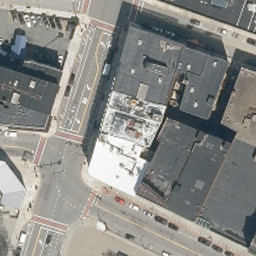

/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/evidence/42.262600_-71.802300/runs/20261107T230726592334Z/utilities.json

/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/evidence/42.262600_-71.802300/runs/20261107T230726592334Z/parcels.json

/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/evidence/42.262600_-71.802300/runs/20261107T230726592334Z/buildings.json

/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/evidence/42.262600_-71.802300/runs/20261107T230726592334Z/lber.json

/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/evidence/42.262600_-71.802300/runs/20261107T230726592334Z/permits.json

/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/evidence/42.262600_-71.802300/runs/20261107T230726592334Z/electrical_permits.json

... (16 outputs left out)

checklist_csv


/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/evidence/42.262600_-71.802300/runs/20261107T230726592334Z/checklist.csv

checklist_parquet


/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/evidence/42.262600_-71.802300/runs/20261107T230726592334Z/checklist.parquet

In [8]:
files = pl.from_dicts(site["evidence"]["files"], infer_schema_length=None)
with pl.Config(tbl_cols=-1, fmt_str_lengths=100):
    display(files.select("kind", "source_title", "status", "source_date", "fetched_at_utc", "local_file"))
assert all(Path(asset["local_file"]).is_file() for asset in site["evidence"]["files"] if asset["status"] == "ok")
display(FileLink(str(Path(site["evidence"]["manifest_file"]).relative_to(Path.cwd()))))
aerial = next((asset for asset in site["evidence"]["files"] if asset["kind"] == "aerial_image" and asset["status"] == "ok"), None)
if aerial:
    display(Image(filename=aerial["local_file"]))

for asset in site["evidence"]["files"]:
    if asset["status"] == "ok":
        display(FileLink(str(Path(asset["local_file"]).relative_to(Path.cwd()))))

display(FileLink(str(Path(site["evidence"]["index_file"]).relative_to(Path.cwd()))))
for name, export in site["evidence"]["exports"].items():
    print(name)
    display(FileLink(str(Path(export["local_file"]).relative_to(Path.cwd()))))


## Documents for the current point

Only documents discovered by the public adapters for the current point are shown here. No separate demonstration property or supplied blueprint is loaded. If this municipality has no archive adapter, that limitation is shown rather than borrowing another town's documents. Only focused intake metadata is modeled; original public documents remain evidence.

In [9]:
archive_example = site
archive_table = table
for name in ["assessor_records", "municipal_archives"]:
    result = site["sources"].get(name, {})
    print(name, result.get("status"), result.get("detail") or result.get("limitations", ""))
archive_files = [f for f in site["evidence"]["files"] if f["kind"] in ("document", "assessor_image") and f.get("source_id") in ("assessor_records", "municipal_archives")]
if archive_files:
    display(pl.from_dicts([{"title": f["source_title"], "status": f["status"], "source_url": f["source_url"], "local_file": f.get("local_file")} for f in archive_files], infer_schema_length=None))
    for f in archive_files:
        if f["status"] == "ok": display(FileLink(str(Path(f["local_file"]).relative_to(Path.cwd()))))
else:
    print("No site-specific assessor images or archive documents were discovered for this point.")

assessor_records unsupported No public assessor adapter configured for this municipality.
municipal_archives unsupported Municipal archive adapter currently covers Holliston, Newton and Northampton; Cambridge permits use separate public datasets.
No site-specific assessor images or archive documents were discovered for this point.


## Save and debug

CSV is convenient for Excel; Parquet preserves nulls and numeric coordinate types. `local_file` points to the backend computer. `file_url` is relative to the API base URL, for example `http://127.0.0.1:8002/evidence/...`. Notebook links below use Jupyter-relative paths so they work when launched from this repository root.


In [10]:
output_dir = Path("data/processed/site_checklist")
output_dir.mkdir(parents=True, exist_ok=True)
table.write_csv(output_dir / "checklist.csv")
table.write_parquet(output_dir / "checklist.parquet")
(output_dir / "site.json").write_text(json.dumps(site, indent=2))
archive_table.write_csv(output_dir / "archive_example_checklist.csv")
print("Saved", table.shape, "to", output_dir.resolve())
errors = table.filter(pl.col("subcategory_name").str.ends_with(".error"))
if errors.height:
    with pl.Config(tbl_rows=-1, tbl_cols=-1, fmt_str_lengths=500):
        display(errors)
else:
    print("No retrieval errors for this lookup.")


Saved (892, 18) to /Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/processed/site_checklist
No retrieval errors for this lookup.


The same dated table is available over HTTP after starting `uv run uvicorn API.server:app --reload --port 8002`:

```python
import requests
response = requests.get(
    "http://127.0.0.1:8002/site/table",
    params={"latitude": LATITUDE, "longitude": LONGITUDE}, timeout=180,
)
response.raise_for_status()
table = pl.from_dicts(response.json())
```

Use `download_evidence=False` in Python or `download_evidence=false` over HTTP to skip the exported evidence packet (source files needed for extraction are still cached). Use `refresh=True` / `refresh=true` to redownload cached files. Provider JSON queries are live on every call. The MVP needs no API keys.


## Independent unknown-location check

These three points are outside the supplied examples. Each is queried directly against public services. A blank address remains blank; no demonstration facility is substituted.

In [11]:
from tempfile import TemporaryDirectory

unknown_results = []
with TemporaryDirectory() as fresh_output:
    for lat, lon in [(42.2626, -71.8023), (42.1015, -72.5898), (42.3876, -71.0995)]:
        result = lookup_site(lat, lon, sources=["parcels"], download_evidence=False, evidence_dir=fresh_output)
        unknown_results.append({**result["location"], "parcel_records": len(result["sources"]["parcels"]["records"]), "checked_at_utc": result["sources"]["parcels"]["checked_at_utc"]})
display(pl.from_dicts(unknown_results, infer_schema_length=None))
assert len({r["municipality"] for r in unknown_results}) == 3

latitude,longitude,municipality,state,address,parcel_records,checked_at_utc
f64,f64,str,str,str,i64,str
42.2626,-71.8023,"""WORCESTER""","""MA""","""455 MAIN ST""",1,"""2026-11-07T23:07:27.823325+00:…"
42.1015,-72.5898,"""SPRINGFIELD""","""MA""","""COURT ST""",1,"""2026-11-07T23:07:28.137533+00:…"
42.3876,-71.0995,"""SOMERVILLE""","""MA""","""101 HIGHLAND AVE""",1,"""2026-11-07T23:07:28.628035+00:…"
